ASSGNMENT NO 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def linear(x):
    return x

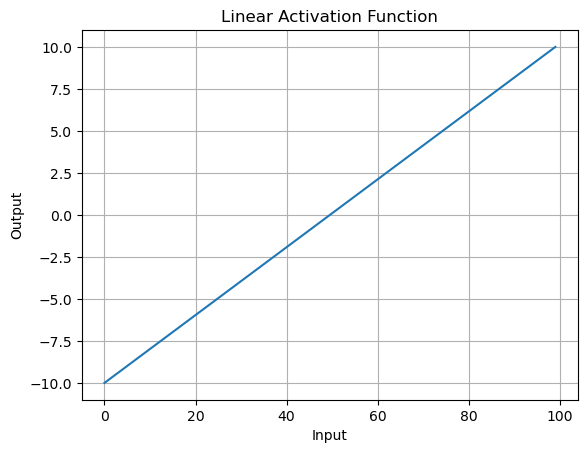

In [3]:
x=np.linspace(-10,10,100)
y=linear(x)
plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Linear Activation Function")
plt.plot(y)
plt.grid()
plt.show()

In [4]:
def sigmoid(x):
    return 1/(1+np.exp(-x))

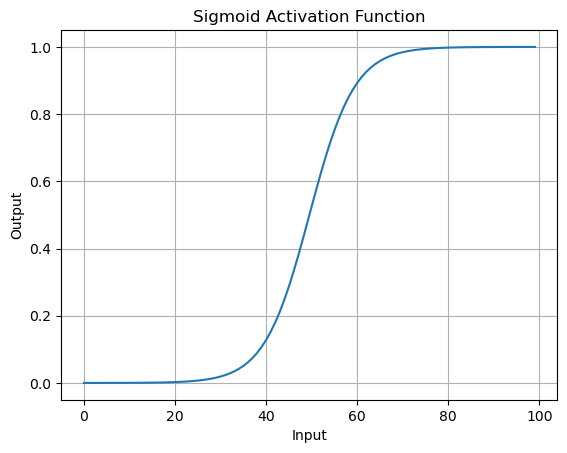

In [5]:
x=np.linspace(-10,10,100)
y=sigmoid(x)
plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Sigmoid Activation Function")
plt.plot(y)
plt.grid()
plt.show()

In [6]:
def relu(x):
    return np.maximum(0,x)

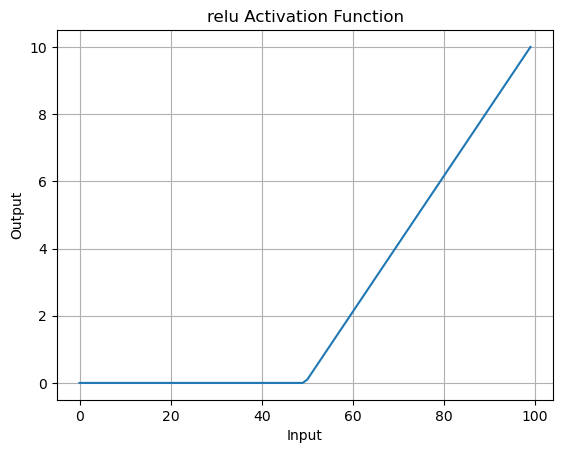

In [7]:
x=np.linspace(-10,10,100)
y=relu(x)
plt.xlabel("Input")
plt.ylabel("Output")
plt.title("relu Activation Function")
plt.plot(y)
plt.grid()
plt.show()

In [8]:
def tanh(x):
    return (np.exp(x)-np.exp(-x))/(np.exp(x)+np.exp(-x))

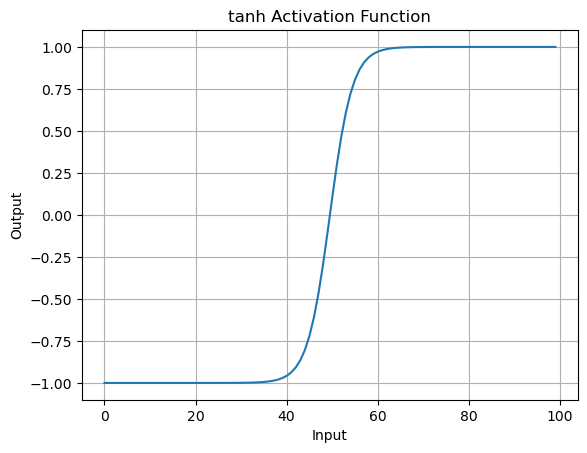

In [9]:
x=np.linspace(-10,10,100)
y=tanh(x)
plt.xlabel("Input")
plt.ylabel("Output")
plt.title("tanh Activation Function")
plt.plot(y)
plt.grid()
plt.show()

In [10]:
def softmax(x):
    return (np.exp(x)/np.sum(np.exp(x),axis=0))

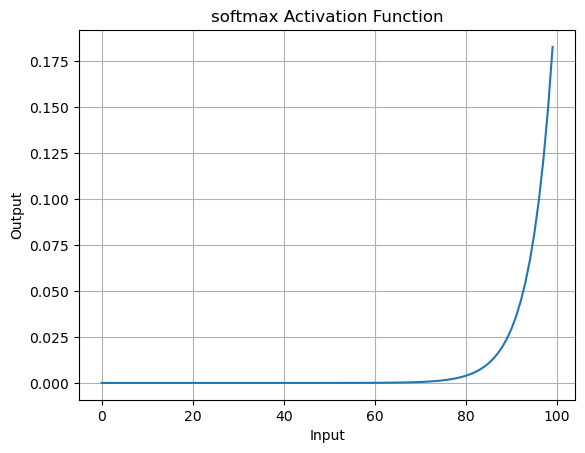

In [11]:
x=np.linspace(-10,10,100)
y=softmax(x)
plt.xlabel("Input")
plt.ylabel("Output")
plt.title("softmax Activation Function")
plt.plot(y)
plt.grid()
plt.show()

In [12]:
def leaky_relu(x,alpha=0.01):
    return np.where(x>0,x,alpha*x)

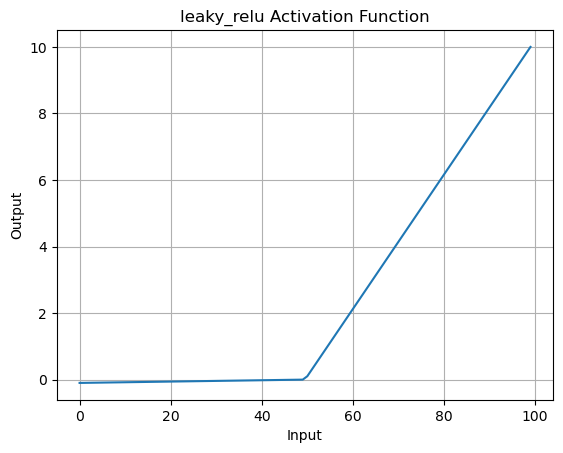

In [13]:
x=np.linspace(-10,10,100)
y=leaky_relu(x)
plt.xlabel("Input")
plt.ylabel("Output")
plt.title("leaky_relu Activation Function")
plt.plot(y)
plt.grid()
plt.show()

ASSIGNMENT NO 2

In [14]:
def mp_neuron(x1,x2,w1,w2,thresold):
    net=x1*w1+x2*w2
    if net>=thresold:
        return 1
    else:
        return 0

In [15]:
print("AND GATE")
print("x1\tx2\ty")
for x1 in [0,1]:
    for x2 in [0,1]:
        y=mp_neuron(x1,x2,1,1,2)
        print(x1,"\t",x2,"\t",y)

AND GATE
x1	x2	y
0 	 0 	 0
0 	 1 	 0
1 	 0 	 0
1 	 1 	 1


In [16]:
print("OR GATE")
print("x1\tx2\ty")
for x1 in [0,1]:
    for x2 in [0,1]:
        y=mp_neuron(x1,x2,1,1,1)
        print(x1,"\t",x2,"\t",y)

OR GATE
x1	x2	y
0 	 0 	 0
0 	 1 	 1
1 	 0 	 1
1 	 1 	 1


ASSIGNMENT NO 3

In [17]:
import numpy as np
from sklearn.linear_model import Perceptron

# Training data: ASCII values 0 to 9
X = np.array([[int(b) for b in format(i, '07b')] for i in range(48, 58)])

# 0 = Even, 1 = Odd
y = np.array([0, 1, 0, 1, 0, 1, 0, 1, 0, 1])

# Create and train model
model = Perceptron()
model.fit(X, y)

# Take input
num = input("Enter a digit (0-9): ")

# Convert into ASCII and Binary
ascii_value = ord(num)
binary_value = format(ascii_value, '07b')

# Prediction
binary_input = [int(b) for b in binary_value]
result = model.predict([binary_input])

# Display output
print("\nNumber:", num)
print("ASCII Value:", ascii_value)
print("Binary Value:", binary_value)

if result[0] == 0:
    print("Result: EVEN")
else:
    print("Result: ODD")

Enter a digit (0-9):  8



Number: 8
ASCII Value: 56
Binary Value: 0111000
Result: EVEN


ASSIGNMENT NO 4

In [18]:
X = [[0, 0],
     [0, 1],
     [1, 0],
     [1, 1]]
y = [0, 0, 0, 1]

In [19]:
def train_perceptron(inputs, targets):
    w1, w2, b = 0.0, 0.0, 0.0
    lr = 0.1
    for epoch in range(20):
        errors = 0
        for i in range(len(inputs)):
            x1, x2 = inputs[i][0], inputs[i][1]
            target = targets[i]
            z = (w1 * x1) + (w2 * x2) + b
            pred = 1 if z >= 0 else 0
            if target != pred:
                error = target - pred
                w1 += lr * error * x1
                w2 += lr * error * x2
                b += lr * error
                errors += 1
        if errors == 0:
            break
    return w1, w2, b

In [20]:
w1, w2, b = train_perceptron(X, y)
print(f"Weights: [{w1:.1f}, {w2:.1f}], Bias: {b:.1f}")

Weights: [0.2, 0.1], Bias: -0.2


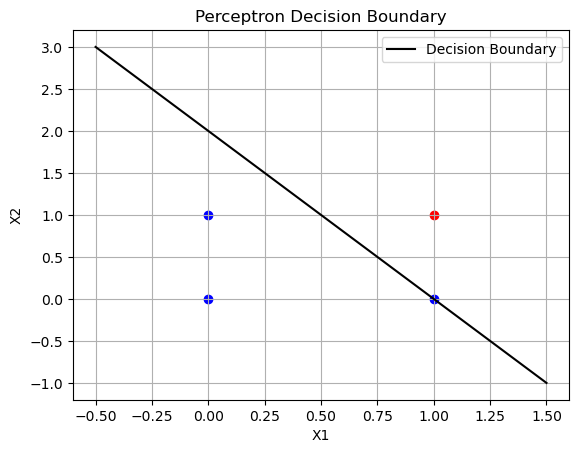

In [21]:
import matplotlib.pyplot as plt

for i in range(len(X)):
    color = 'red' if y[i] == 1 else 'blue'
    plt.scatter(X[i][0], X[i][1], color=color)

# Decision boundary
x = [-0.5, 1.5]
y_line = [-(w1 * i + b) / w2 for i in x]

plt.plot(x, y_line, color='black', label='Decision Boundary')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Perceptron Decision Boundary')
plt.grid()
plt.legend()
plt.show()

ASSIGNMENT NO 5

In [22]:

import numpy as np

# Two pairs of bipolar vectors
X = np.array([
    [1, -1, 1],
    [-1, 1, -1]
])

Y = np.array([
    [1, -1],
    [-1, 1]
])

# Calculate weight matrix
W = np.zeros((3, 2))

for i in range(2):
    W += np.outer(X[i], Y[i])

print("Weight Matrix:")
print(W)

# Recall Y from X
print("\nForward Recall (X -> Y):")

for x in X:
    y = np.sign(np.dot(x, W))
    print("Input:", x, "Output:", y)

# Recall X from Y
print("\nBackward Recall (Y -> X):")

for y in Y:
    x = np.sign(np.dot(y, W.T))
    print("Input:", y, "Output:", x)


Weight Matrix:
[[ 2. -2.]
 [-2.  2.]
 [ 2. -2.]]

Forward Recall (X -> Y):
Input: [ 1 -1  1] Output: [ 1. -1.]
Input: [-1  1 -1] Output: [-1.  1.]

Backward Recall (Y -> X):
Input: [ 1 -1] Output: [ 1. -1.  1.]
Input: [-1  1] Output: [-1.  1. -1.]


ASSIGNMENT NO 6

In [23]:
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

In [24]:
digit_0 = [
        [1, 1, 1],
        [1, 0, 1],
        [1, 0, 1],
        [1, 0, 1],
        [1, 1, 1]
    ]
digit_1 = [
        [0, 1, 0],
        [1, 1, 0],
        [0, 1, 0],
        [0, 1, 0],
        [1, 1, 1]
    ]
digit_2 = [
        [1, 1, 1],
        [0, 0, 1],
        [1, 1, 1],
        [1, 0, 0],
        [1, 1, 1]
    ]
digit_3 = [
        [1, 1, 1],
        [0, 0, 1],
        [1, 1, 1],
        [0, 0, 1],
        [1, 1, 1]
    ]
digit_4 = [
        [1, 0, 1],
        [1, 0, 1],
        [1, 1, 1],
        [0, 0, 1],
        [0, 0, 1]

    ]
digit_5 = [
        [1, 1, 1],
        [1, 0, 0],
        [1, 1, 1],
        [0, 0, 1],
        [1, 1, 1]
    ]
digit_6 = [
        [1, 1, 1],
        [1, 0, 0],
        [1, 1, 1],
        [1, 0, 1],
        [1, 1, 1]
    ]
digit_7 = [
        [1, 1, 1],
        [0, 0, 1],
        [0, 0, 1],
        [0, 0, 1],
        [0, 0, 1]
    ]
digit_8 = [
        [1, 1, 1],
        [1, 0, 1],
        [1, 1, 1],
        [1, 0, 1],
        [1, 1, 1]
    ]
digit_9 = [
        [1, 1, 1],
        [1, 0, 1],
        [1, 1, 1],
        [0, 0, 1],
        [1, 1, 1]
    ]

In [25]:
X=np.array([digit_0,
            digit_1,
            digit_2,
            digit_3,
            digit_4,
            digit_5,
            digit_6,
            digit_7,
            digit_8,
            digit_9])
X=X.reshape(10,15)
y=np.array([0,1,2,3,4,5,6,7,8,9])

In [26]:
model = MLPClassifier(
    hidden_layer_sizes=(15,),
    activation='relu',
    solver='lbfgs',
    max_iter=5000,
    random_state=42
)

In [27]:
model.fit(X,y)

,hidden_layer_sizes,"(15,)"
,activation,'relu'
,solver,'lbfgs'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,5000
,shuffle,True
,random_state,42


In [28]:
y_pred=model.predict(X)

In [29]:
accuracy_score(y,y_pred)

1.0

In [30]:
print("Actual Digits:",y)
print("Predicted Digits:",y_pred)

Actual Digits: [0 1 2 3 4 5 6 7 8 9]
Predicted Digits: [0 1 2 3 4 5 6 7 8 9]


In [31]:
test_digit = np.array([
        [1, 1, 1],
        [1, 0, 1],
        [1, 1, 1],
        [0, 0, 1],
        [0, 1, 1]
    ])
test_input=test_digit.reshape(1,15)
pred=model.predict(test_input)
print("Prediction:",pred)

Prediction: [9]
